In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib

# 주식 정보 읽어오기

FinanceDataReader는 한국과 미국을 비롯한 글로벌 금융 시장의 주식, 지수, 암호화폐 등 다양한 금융 데이터와 종목 리스트를 손쉽게 수집하고 분석할 수 있도록 도와주는 파이썬 라이브러리로 복잡한 웹 크롤링이나 API 인증 과정 없이 몇 줄의 코드로 다양한 거래소의 데이터를 판다스 데이터프레임 형태로 가져올 수 있어, 주가 분석이나 퀀트 투자 등에 널리 쓰인다.

주식 정보(거래소, 종목)를 읽어오기 위해서 FinanceDataReader를 설치하고 import 한다.  
`!pip install finance-DataReader`

In [2]:
import FinanceDataReader as fdr

FinanceDataReader에서 제공하는 종목 리스트는 거래소 및 시장별로 세분화되어 있고 거래소 정보를 얻어오는 `StockListing('시장키워드')`를 사용한다.

## 한국 시장 전 종목 및 특수 리스트  
fdr.StockListing(`'KRX'`) # `KRX 전체`(코스피 + 코스닥 + 코넥스)  
fdr.StockListing(`'KOSPI'`) # `코스피`  
fdr.StockListing(`'KOSDAQ'`) # `코스닥`  
fdr.StockListing(`'KONEX'`) # `코넥스`  
fdr.StockListing(`'KRX-DELISTING'`) # `상장폐지 종목`  
fdr.StockListing(`'KRX-ADMINISTRATIVE'`) # `관리종목`  
fdr.StockListing(`'KRX-MARCAP'`) # `시가총액 순 정렬`

## 미국 시장 및 주요 지수 구성 종목
fdr.StockListing(`'S&P500'`) # `S&P 500`  
fdr.StockListing(`'NASDAQ'`) # `나스닥 거래소`  
fdr.StockListing(`'NYSE'`) # `뉴욕 증권 거래소`  
fdr.StockListing(`'AMEX'`) # `아멕스 거래소`

## 글로벌 해외 주요 거래소
fdr.StockListing(`'SSE'`) # `상해(중국)`  
fdr.StockListing(`'SZSE'`) # `심천(중국)`  
fdr.StockListing(`'HKEX'`) # `홍콩`  
fdr.StockListing(`'TSE'`) # `도쿄(일본)`  
fdr.StockListing(`'HOSE'`) # `호치민(베트남)`

## ETF 리스트
fdr.StockListing(`'ETF/KR'`) # `국내 상장 ETF 전체`

## 대한민국 주식 정보 가져오기

In [4]:
fdr.StockListing('KOSPI')

,Code,ISU_CD,Name,Market,Dept,Close,ChangeCode,Changes,ChagesRatio,Open,High,Low,Volume,Amount,Marcap,Stocks,MarketId,lateInfoMsgCd
0,095570,KR7095570008,AJ네트웍스,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45252759,STK,ME005
1,006840,KR7006840003,AK홀딩스,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13247561,STK,ME005
2,027410,KR7027410000,BGF,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,95716791,STK,ME005
3,282330,KR7282330000,BGF리테일,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17283906,STK,ME005
4,138930,KR7138930003,BNK금융지주,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,306839751,STK,ME005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
931,079980,KR7079980009,휴비스,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34500000,STK,ME005
932,005010,KR7005010004,휴스틸,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56188075,STK,ME005
933,000540,KR7000540005,흥국화재,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64242645,STK,ME005
934,000545,KR7000541003,흥국화재우,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,768000,STK,ME005


특정 종목에 대한 정보를 얻어오려면 `fdr.DataReader('종목코드'[, '시작일'[, '종료일']])`를 사용한다.

`Date`: 날짜    
`Open`: 해당 거래일의 장 시작시 체결된 첫 가격  
`High`: 해당 거래일 동안 주가가 기록한 가장 높은 가격  
`Low`: 해당 거래일 동안 주가가 기록한 가장 낮은 가격  
`Close`: 해당 거래일의 장 마감시 체결된 마지막 가격, 주가 분석 시 가장 흔하게 기준값으로 사용된다.  
`Volume`: 해당 거래일 동안 매매가 체결된 주식의 총 수량  
`Change`: 전일 종가 대비 당일 종가의 등락 변동 백분율

삼성전자(005930)의 상장일 부터 현재까지 주가 정보를 얻어온다.

In [5]:
fdr.DataReader('005930')

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2014-08-20,25280,25420,25020,25220,188612,NaN
2014-08-21,25100,25220,24620,24700,342108,-0.020619
2014-08-22,24900,24940,24700,24940,168153,0.009717
2014-08-25,24620,24620,24420,24560,231544,-0.015237
2014-08-26,24700,24700,24420,24440,214389,-0.004886
...,...,...,...,...,...,...
2026-11-06,180000,196500,179200,193500,35516270,-0.039702
2026-11-09,187200,195400,183800,187000,19855892,-0.033592
2026-11-10,199400,201500,196400,197300,15289184,0.055080


삼성전자(005930)의 2023-01-01 부터 현재까지 주가 정보를 얻어온다.

In [6]:
fdr.DataReader('005930', '2023-01-01')

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2023-01-02,55500,56100,55200,55500,10031448,0.003617
2023-01-03,55400,56000,54500,55400,13547030,-0.001802
2023-01-04,55700,58000,55600,57800,20188071,0.043321
2023-01-05,58200,58800,57600,58200,15682826,0.006920
2023-01-06,58300,59400,57900,59000,17334989,0.013746
...,...,...,...,...,...,...
2026-11-06,180000,196500,179200,193500,35516270,-0.039702
2026-11-09,187200,195400,183800,187000,19855892,-0.033592
2026-11-10,199400,201500,196400,197300,15289184,0.055080


삼성전자(005930)의 2025년 주가 정보를 얻어온다.

In [7]:
samsung_df = fdr.DataReader('005930', '2025-01-01', '2025-12-31')
samsung_df

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2025-01-02,52700,53600,52300,53400,16630538,0.003759
2025-01-03,52800,55100,52800,54400,19318046,0.018727
2025-01-06,54400,56200,54300,55900,19034284,0.027574
2025-01-07,56800,57300,55400,55400,17030235,-0.008945
2025-01-08,54800,57500,54700,57300,26593553,0.034296
...,...,...,...,...,...,...
2025-12-23,110900,112500,110400,111500,20419187,0.009050
2025-12-24,112400,112400,110900,111100,12492939,-0.003587
2025-12-26,112400,117000,112400,117000,34018174,0.053105


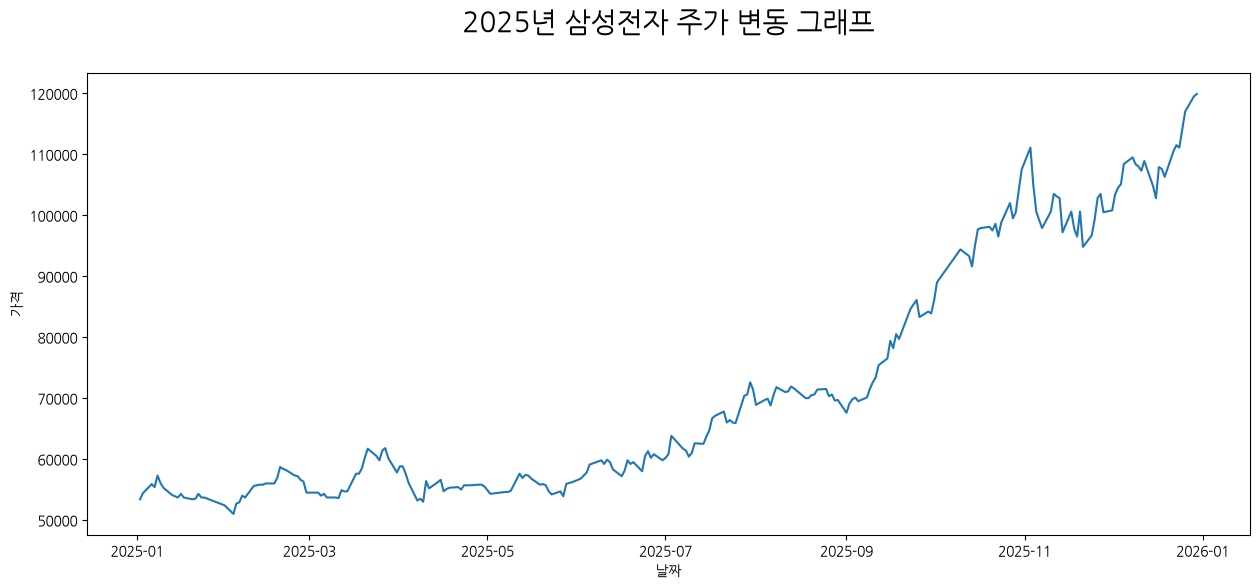

In [8]:
plt.figure(figsize=[15, 6])
sns.lineplot(data=samsung_df, x=samsung_df.index, y=samsung_df.Close)
plt.title('2025년 삼성전자 주가 변동 그래프', pad=30, fontsize=20)
plt.xlabel('날짜')
plt.ylabel('가격')
plt.show()

## 미국 주식 정보 가져오기

In [9]:
fdr.StockListing('NASDAQ').head(10)

100%|██████████| 3983/3983 [00:06<00:00, 571.97it/s]


,Symbol,Name,IndustryCode,Industry
0,AAPL,Apple Inc.,57106020,전화 및 소형 장치
1,NVDA,NVIDIA Corporation,57101010,반도체
2,MSFT,Microsoft Corporation,57201020,소프트웨어
3,AMZN,Amazon.com Inc,53402010,백화점
4,GOOGL,Alphabet Inc. Class A,57201030,온라인 서비스
5,SPCX,Space Exploration Technologies Corp,57401020,무선 통신 서비스
6,AVGO,Broadcom Inc,57101010,반도체
7,META,Meta Platforms Inc.,57201030,온라인 서비스
8,GOOG,Alphabet Inc. Class C,57201030,온라인 서비스
9,TSLA,Tesla Inc,53101010,자동차 및 트럭 제조


애플(AAPL)의 2025년 주가 정보를 얻어온다.

In [10]:
apple_df = fdr.DataReader('AAPL', '2025-01-01', '2025-12-31')
apple_df

,Open,High,Low,Close,Volume,Adj Close
2024-12-31,252.440002,253.279999,249.429993,250.419998,39480700,248.615784
2025-01-02,248.929993,249.100006,241.820007,243.850006,55740700,242.093124
2025-01-03,243.360001,244.179993,241.889999,243.360001,40244100,241.606644
2025-01-06,244.309998,247.330002,243.199997,245.000000,45045600,243.234848
2025-01-07,242.979996,245.550003,241.350006,242.210007,40856000,240.464966
...,...,...,...,...,...,...
2025-12-23,270.839996,272.500000,269.559998,272.359985,29642000,271.620667
2025-12-24,272.339996,275.429993,272.200012,273.809998,17910600,273.066711
2025-12-26,274.160004,275.369995,272.859985,273.399994,21521800,272.657806
2025-12-29,272.690002,274.359985,272.350006,273.760010,23715200,273.016876


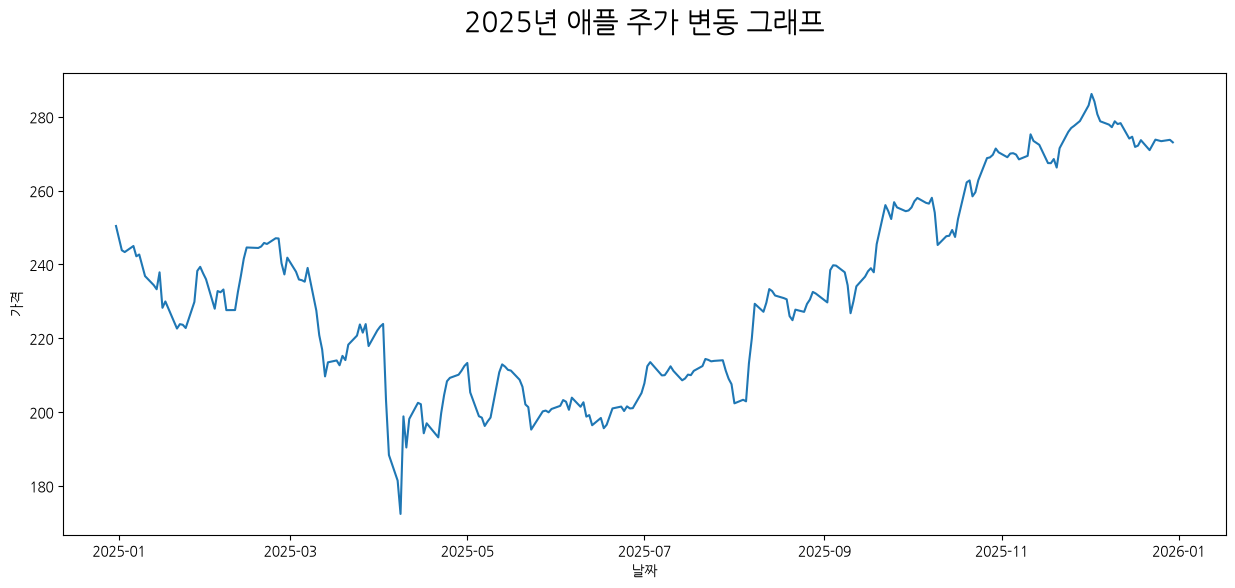

In [11]:
plt.figure(figsize=[15, 6])
sns.lineplot(data=apple_df, x=apple_df.index, y=apple_df.Close)
plt.title('2025년 애플 주가 변동 그래프', pad=30, fontsize=20)
plt.xlabel('날짜')
plt.ylabel('가격')
plt.show()

# 시계열 데이터

## 시계열 데이터 패턴

`추세(trand)`: 시계열 데이터가 시간에 따라서 증가하거나 감소하는 경향을 보이는 패턴  
`계절성(seasonality)`: 시계열 데이터가 일정한 주기를 가지고 반복되는 패턴  
`순환성(cyclical)`: 추세와는 달리, 일정한 주기를 가지고 반복되지만 주기의 길이가 일정하지 않은 패턴  
`불규칙성(irregular)`: 지진, 홍수, 파업, 코로나와 같은 특수한 요인에 의해 발생하는 불규칙한 패턴

## 시계열 데이터 분석

`분해법`: 시계열 데이터가 가지는 추세, 계절성, 주기, 불규칙성과 같은 구성요소를 분해해서 분석  
`시간 영역 분석법`  
① 자기 회귀(Auto Regressive, AR) 모형  
&nbsp;&nbsp;&nbsp;현재의 시계열 값이 과거의 자기 자신의 값들에 영향을 받는다고 가정하는 모형이다. 즉, '어제의 나, 그제의 나'가 오늘의 나를 만든다는 개념이다.  
② 이동 평균(Moving Average, MA) 모형  
&nbsp;&nbsp;&nbsp;현재의 시계열 값이 과거의 오차(white noise, 백색 잡음)들의 선형 결합으로 이루어져 있다고 보는 모형이다.  
③ 자기 회귀 이동 평균(Auto Regressive Moving Average, ARMA) 모형  
&nbsp;&nbsp;&nbsp;시계열 데이터가 있을 때 AR 특성과 MA 특성을 동시에 가지고 있을 때 사용하는 모형이다.  
④ 자기 회귀 누적 이동 평균(Auto Regressive Integrated Moving Average, ARIMA) 모형  
&nbsp;&nbsp;&nbsp;ARMA 모형의 한계를 극복하기 위해, 차분 단계를 추가한 모형이다.

# 시계열 데이터 전처리

## 시계열 데이터 만들기

In [12]:
df = pd.DataFrame(
    {'date': ['2022-01-03', '2024-11-22', '2025-01-15'], 'name': ['홍길동', '임꺽정', '장길산']}
)
df

,date,name
0,2022-01-03,홍길동
1,2024-11-22,임꺽정
2,2025-01-15,장길산


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   date    3 non-null      str  
 1   name    3 non-null      str  
dtypes: str(2)
memory usage: 180.0 bytes


to_datetime() 메소드로 str 타입을 datetime 타입으로 변환한다.

In [14]:
df['date'] = pd.to_datetime(df.date)

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    3 non-null      datetime64[us]
 1   name    3 non-null      str           
dtypes: datetime64[us](1), str(1)
memory usage: 180.0 bytes


set_index() 메소드로 특정 시리즈(컬럼)을 인덱스로 설정할 수 있다.

In [16]:
df = df.set_index(['date'])
df

,name
date,
2022-01-03,홍길동
2024-11-22,임꺽정
2025-01-15,장길산


In [17]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 3 entries, 2022-01-03 to 2025-01-15
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   name    3 non-null      str  
dtypes: str(1)
memory usage: 48.0 bytes


## 결측치 처리

결측치 확인

isnull() 메소드 또는 isna() 메소드 실행 결과에 sum() 메소드를 실행하면 결측치의 개수를 확인할 수 있다.

In [18]:
df = pd.DataFrame(
    {'date': ['2022-01-03', '2024-11-22', '2024-12-01', '2025-01-15'], 'name': [0.1, 2.0, np.nan, 1.2]}
)
df['date'] = pd.to_datetime(df.date)
df = df.set_index(['date'])
df

,name
date,
2022-01-03,0.1
2024-11-22,2.0
2024-12-01,NaN
2025-01-15,1.2


In [19]:
df.isnull().sum()

name    1
dtype: int64

결측치 제거

dropna() 메소드로 결측치를 제거할 수 있다.

`axis`: 0이 기본값이고 결측치가 포함된 행을 제거하고, 1을 결측치가 포함된 열을 제거한다.

In [20]:
df.dropna()

,name
date,
2022-01-03,0.1
2024-11-22,2.0
2025-01-15,1.2


결측치를 특정 데이터로 채우기

`fillna()` 메소드로 특정 값으로 결측치를 채운다.  
`ffill()` 메소드로 이전 값으로 결측치를 채운다.  
`bfill()` 메소드로 다음 값으로 결측치를 채운다.  
`interpolate()` 메소드로 이전 값과 다음 값의 평균으로 결측치를 채운다.

In [23]:
df.fillna('특정값')

,name
date,
2022-01-03,0.1
2024-11-22,2.0
2024-12-01,특정값
2025-01-15,1.2


In [21]:
df.ffill()

,name
date,
2022-01-03,0.1
2024-11-22,2.0
2024-12-01,2.0
2025-01-15,1.2


In [22]:
df.bfill()

,name
date,
2022-01-03,0.1
2024-11-22,2.0
2024-12-01,1.2
2025-01-15,1.2


In [24]:
df.interpolate()

,name
date,
2022-01-03,0.1
2024-11-22,2.0
2024-12-01,1.6
2025-01-15,1.2


## 시계열 데이터 주기(frequency) 변환

In [30]:
df = pd.DataFrame(
    {'date': ['2021-01-03', '2024-11-22', '2024-12-01', '2025-01-15'], 'name': [0.1, 2.0, 1.6, 1.2]}
)
df['date'] = pd.to_datetime(df.date)
df = df.set_index(['date'])
df

,name
date,
2021-01-03,0.1
2024-11-22,2.0
2024-12-01,1.6
2025-01-15,1.2


In [31]:
df.index

DatetimeIndex(['2021-01-03', '2024-11-22', '2024-12-01', '2025-01-15'],
              dtype='datetime64[us]', name='date', freq=None)

asfreq() 메소드는 시계열 데이터의 주기를 변환할 때 사용한다.  

`freq`: 필수, 속성은 변경하고자 하는 시계열 데이터의 주기를 지정한다.  

① 연/분기/월 단위 (macro)주기  
&nbsp;&nbsp;&nbsp;`YE`(Year-End): 매년 12월 31일(연말)  
&nbsp;&nbsp;&nbsp;`YS`(Year-Start): 매년 1월 1일(연초)  
&nbsp;&nbsp;&nbsp;`QE`(Quarter-End): 매년 분기 말  
&nbsp;&nbsp;&nbsp;`QS`(Quarter-End): 매년 분기 초  
&nbsp;&nbsp;&nbsp;`ME`(Month-End): 매월 말  
&nbsp;&nbsp;&nbsp;`MS`(Month-Start): 매월 초  

② 주/일 단위 (standard)주기  
&nbsp;&nbsp;&nbsp;`D`(Daily): 매일, 24시간 간격  
&nbsp;&nbsp;&nbsp;`B`(Business Day): 매일, 주말/공휴일을 제외한 영업일 기준  
&nbsp;&nbsp;&nbsp;`금융/주식 데이터는 주말이나 공휴일이 포함된 데이터에 'D'를 쓰면 주말 데이터가 비어서 nan이 될 수 있으므로 주말을 알아서 건너뛰는 'B'를 사용한다.`  
&nbsp;&nbsp;&nbsp;`W`(Weekly): 매주 일요일, 필요하다면 'W-MON', 'W-FRI' 처럼 특정 요일을 지정할 수 있다.

③ 시/분/초 단위 주기 (micro)주기  
&nbsp;&nbsp;&nbsp;`h`(hour): 매 시간  
&nbsp;&nbsp;&nbsp;`min`(minute)매 분  
&nbsp;&nbsp;&nbsp;`s`(second)매 초

기본 단위 앞에 `숫자`를 붙이면 원하는 배수만큼 주기를 변경할 수 있다.  
&nbsp;&nbsp;&nbsp;`3D`: 3일 간격  
&nbsp;&nbsp;&nbsp;`2h`: 2시간 간격  
&nbsp;&nbsp;&nbsp;`30min`: 30분 간격

`method`: 주기를 변경할 때 생기는 결측치를 채우는 방식을 지정한다.  
`fill_value`: 주기가 변경될 때 생기는 결측치를 일괄적으로 채울 특정 값을 지정한다.  

In [36]:
df.asfreq(freq='YE', method='ffill')

,name
date,
2021-12-31,0.1
2022-12-31,0.1
2023-12-31,0.1
2024-12-31,1.6


## 이동 연산

In [37]:
df = pd.DataFrame(
    {'date': ['2021-01-03', '2024-11-22', '2024-12-01', '2024-12-20', '2025-01-15'], 'x': [5, 4, 3, 2, 7]}
)
df['date'] = pd.to_datetime(df.date)
df = df.set_index(['date'])
df

,x
date,
2021-01-03,5
2024-11-22,4
2024-12-01,3
2024-12-20,2
2025-01-15,7


rolling() 메소드는 시계열이나 순차적인 데이터에서 구간별 이동 연산을 수행한다.  

일정한 크기의 구간(창, window)을 지정한 뒤, 이 구간을 데이터의 처음부터 끝까지 슬라이딩 방식으로 이동시키면서 합계, 평균, 표준편차 등의 집계 함수를 적용할 수 있다. 주식 시장의 `이동 평균선`이나 센서 데이터의 노이즈 제거 등에 사용한다.

`window`: 필수, 속성은 이동 윈도우의 크기(묶을 데이터의 개수)를 지정한다.  
`min_periods`: 집계 함수를 적용할 데이터 개수가 부족해도 있는 만큼만 가지고 계산할 수 있게 한다. nan이 발생하지 않게하려면 1을 지정하면 된다.

In [40]:
df.rolling(window=1).mean()

,x
date,
2021-01-03,5.0
2024-11-22,4.0
2024-12-01,3.0
2024-12-20,2.0
2025-01-15,7.0


In [44]:
df.rolling(window=2, min_periods=1).mean()

,x
date,
2021-01-03,5.0
2024-11-22,4.5
2024-12-01,3.5
2024-12-20,2.5
2025-01-15,4.5


In [42]:
df.rolling(window=3).mean()

,x
date,
2021-01-03,NaN
2024-11-22,NaN
2024-12-01,4.0
2024-12-20,3.0
2025-01-15,4.0


## 이전 값과의 차이 계산

In [45]:
df = pd.DataFrame(
    {'date': ['2021-01-03', '2024-11-22', '2024-12-01', '2024-12-20', '2025-01-15'], 'x': [5, 4, 3, 2, 7]}
)
df['date'] = pd.to_datetime(df.date)
df = df.set_index(['date'])
df

,x
date,
2021-01-03,5
2024-11-22,4
2024-12-01,3
2024-12-20,2
2025-01-15,7


diff() 메소드는 데이터프레임이나 시리즈에서 현재 행(또는 열)의 값과 이전 행(또는 열)의 값 사이의 차이를 계산한다.

`periods`: 1이 기본값이고 차이를 계산할 대상과의 간격을 지정한다. 1은 현재 행과 위쪽 행(7 - 2)과 차이, -1은 현재 행과 아래쪽 행의 차이를 계산한다.  
`axis`: 0이 기본값이고 0은 행 기준으로 위아래 데이터 간의 차이를 계산하고 1은 열 기준으로 좌우 데이터 간의 차이를 계산한다.

In [48]:
df2 = df.diff(periods=1, axis=0)
df2.columns = ['diff']
df2

,diff
date,
2021-01-03,NaN
2024-11-22,-1.0
2024-12-01,-1.0
2024-12-20,-1.0
2025-01-15,5.0


concat() 메소드는 여러개의 데이터프레임을 합친다.  
`axis`: 기본값은 0이고 아래쪽으로 합친다. 1을 지정하면 오른쪽으로 합친다.

In [50]:
pd.concat([df, df2], axis=1)

,x,diff
date,,
2021-01-03,5,NaN
2024-11-22,4,-1.0
2024-12-01,3,-1.0
2024-12-20,2,-1.0
2025-01-15,7,5.0


## 데이터 밀어내기

In [52]:
df = pd.DataFrame(
    {'date': ['2021-01-03', '2024-11-22', '2024-12-01', '2024-12-20', '2025-01-15'], 'x': [5, 4, 3, 2, 7]}
)
df['date'] = pd.to_datetime(df.date)
df = df.set_index(['date'])
df

,x
date,
2021-01-03,5
2024-11-22,4
2024-12-01,3
2024-12-20,2
2025-01-15,7


shift() 메소드는 데이터프레임이나 시리즈에서 데이터를 지정한 수치만큼 위나 아래로 밀어낸다.  
인덱스는 그대로 둔 채 값들만 움직이기 때문에, 시계열 데이터에서 과거의 데이터를 현재로 끌어오거나 반대로 미래의 데이터를 당겨올 대 사용한다.

`periods`: 기본값은 1이고 데이터를 끌어오거나 당겨올 칸 수를 지정한다. 양수는 과거의 데이터가 현재로 오고, 음수는 미래의 데이터가 현재로 온다.

In [56]:
df['shift'] = df.x.shift(periods=2)
df

,x,shift
date,,
2021-01-03,5,NaN
2024-11-22,4,NaN
2024-12-01,3,5.0
2024-12-20,2,4.0
2025-01-15,7,3.0


## One-Hot Encoding

범주형(categorical) 데이터를 컴퓨터가 처리할 수 있는 형태로 변환하는 방법 중 하나로 모두 `0`으로 표시하고 현재 데이터만 `1`로 표시하는 방법이다.

In [57]:
df = pd.DataFrame(
    {'color': ['red', 'green', 'blue', 'green', 'red']}
)
df

,color
0,red
1,green
2,blue
3,green
4,red


get_dummies() 메소드는 데이터 분석이나 기계학습에서 범주형 데이터를 원-핫 인코딩하여 파생 변수로 만들어준다.

In [60]:
pd.get_dummies(df.color, dtype=int)

,blue,green,red
0,0,0,1
1,0,1,0
2,1,0,0
3,0,1,0
4,0,0,1


## 시계열 데이터 그룹화

resample() 메소드는 시계열 데이터의 빈도를 확인할 때 사용한다.

`rule`: 필수, 데이터를 어떤 시간 간격과 주기로 그룹화할 지 결정한다.

① 시간 및 세부 단위: 하루보다 짧은 시간 간격으로 데이터를 쪼갠다.  
`ns`: 나노초  
`us`: 마이크로초  
`ms`: 밀리초  
`s`: 초, 30s(30초 간격으로)  
`min`: 분, 5min(5분 간격으로)  
`h`: 시, 4h(4시간 간격으로)

② 일 및 주 단위: 날짜를 기준으로 묶는다.  
`D`: 달력 기준 하루, 3D(3일 간격으로)  
`B`: 영업일 기준 하루  
`W`: 주, 기본적으로 일요일 기준  

③ 월 단위: 월말 또는 월초를 기준으로 묶는다.  
`ME`: 월말, 2ME(2개월 말 간격으로)  
`MS`: 월초  
`BME`: 영업일 기준 월말  
`BMS`: 영업일 기준 월초  
`SM`(Semi-Month End): 매월 15일과 말일  

④ 분기 및 연 단위: 장기 시계열 데이터를 다룰때 사용한다.  
`QE`: 분기말  
`QS`: 분기초  
`BQE`: 영업일 기준 분기말  
`YE`: 연말  
`YS`: 연초  
`BYE`: 영업일 기준 연말

In [64]:
samsung_df.resample('BME').mean()

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2025-01-31,54238.888889,55044.444444,53750.000000,54361.111111,1.904949e+07,-0.000711
2025-02-28,55465.000000,56220.000000,55025.000000,55665.000000,2.123153e+07,0.002120
2025-03-31,57075.000000,57960.000000,56535.000000,57260.000000,2.078140e+07,0.003160
2025-04-30,55840.909091,56372.727273,55286.363636,55686.363636,1.460492e+07,-0.001606
2025-05-30,55705.263158,56336.842105,55189.473684,55652.631579,1.400887e+07,0.000811
2025-06-30,59315.789474,59936.842105,58568.421053,59200.000000,1.917143e+07,0.003443
2025-07-31,64891.304348,65786.956522,64039.130435,65086.956522,2.137355e+07,0.007976
2025-08-29,70810.000000,71300.000000,70065.000000,70470.000000,1.414719e+07,-0.001104
2025-09-30,76677.272727,77595.454545,75900.000000,77022.727273,1.862918e+07,0.008649


In [65]:
samsung_df.resample('BQE').mean()

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2025-03-31,55639.655172,56455.172414,55150.000000,55810.344828,2.039913e+07,0.001600
2025-06-30,56898.333333,57490.000000,56295.000000,56788.333333,1.586223e+07,0.000758
2025-09-30,70701.538462,71480.000000,69907.692308,70783.076923,1.822119e+07,0.005410
2025-12-31,102355.932203,103833.898305,100949.152542,102461.016949,2.282382e+07,0.006444


pct_change() 메소드로 전일 종가 대비 당일 종가의 등락 변동 백분율을 계산할 수 있다.

In [67]:
apple_df['Change'] = apple_df.Close.pct_change()
apple_df

,Open,High,Low,Close,Volume,Adj Close,Change
2024-12-31,252.440002,253.279999,249.429993,250.419998,39480700,248.615784,NaN
2025-01-02,248.929993,249.100006,241.820007,243.850006,55740700,242.093124,-0.026236
2025-01-03,243.360001,244.179993,241.889999,243.360001,40244100,241.606644,-0.002009
2025-01-06,244.309998,247.330002,243.199997,245.000000,45045600,243.234848,0.006739
2025-01-07,242.979996,245.550003,241.350006,242.210007,40856000,240.464966,-0.011388
...,...,...,...,...,...,...,...
2025-12-23,270.839996,272.500000,269.559998,272.359985,29642000,271.620667,0.005130
2025-12-24,272.339996,275.429993,272.200012,273.809998,17910600,273.066711,0.005324
2025-12-26,274.160004,275.369995,272.859985,273.399994,21521800,272.657806,-0.001497
2025-12-29,272.690002,274.359985,272.350006,273.760010,23715200,273.016876,0.001317


# 주식 시세 시각화

## 수익율 시각화

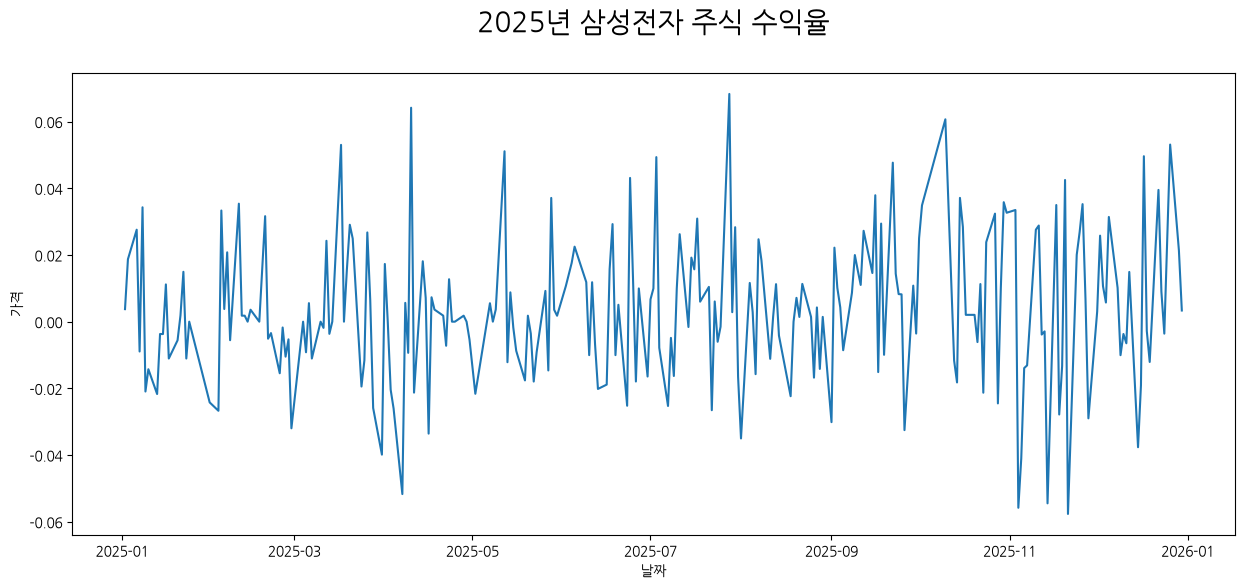

In [69]:
plt.figure(figsize=[15, 6])
sns.lineplot(data=samsung_df, x=samsung_df.index, y=samsung_df.Change)
plt.title('2025년 삼성전자 주식 수익율', pad=30, fontsize=20)
plt.xlabel('날짜')
plt.ylabel('가격')
plt.show()

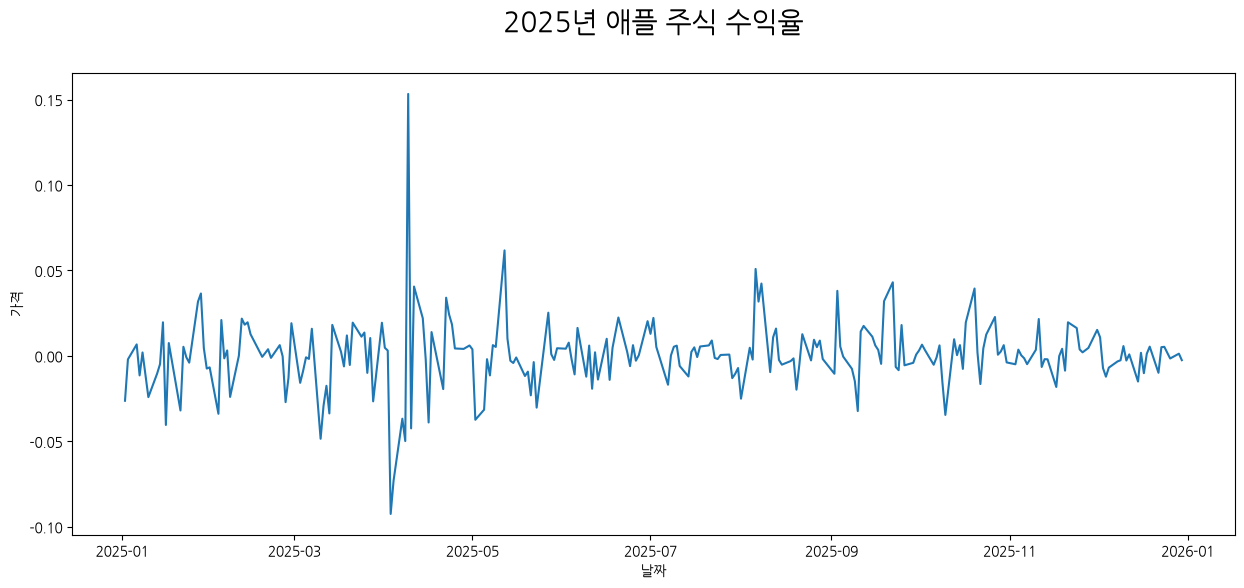

In [70]:
plt.figure(figsize=[15, 6])
sns.lineplot(data=apple_df, x=apple_df.index, y=apple_df.Change)
plt.title('2025년 애플 주식 수익율', pad=30, fontsize=20)
plt.xlabel('날짜')
plt.ylabel('가격')
plt.show()

## 주가 흐름 시각화

2달 종가 이동 평균 시각화

In [71]:
samsung_month_df = samsung_df.resample('BME').mean()
samsung_month_df

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2025-01-31,54238.888889,55044.444444,53750.000000,54361.111111,1.904949e+07,-0.000711
2025-02-28,55465.000000,56220.000000,55025.000000,55665.000000,2.123153e+07,0.002120
2025-03-31,57075.000000,57960.000000,56535.000000,57260.000000,2.078140e+07,0.003160
2025-04-30,55840.909091,56372.727273,55286.363636,55686.363636,1.460492e+07,-0.001606
2025-05-30,55705.263158,56336.842105,55189.473684,55652.631579,1.400887e+07,0.000811
2025-06-30,59315.789474,59936.842105,58568.421053,59200.000000,1.917143e+07,0.003443
2025-07-31,64891.304348,65786.956522,64039.130435,65086.956522,2.137355e+07,0.007976
2025-08-29,70810.000000,71300.000000,70065.000000,70470.000000,1.414719e+07,-0.001104
2025-09-30,76677.272727,77595.454545,75900.000000,77022.727273,1.862918e+07,0.008649


In [72]:
samsung_month_df['MA2'] = samsung_month_df.Close.rolling(window=2, min_periods=1).mean()
samsung_month_df

,Open,High,Low,Close,Volume,Change,MA2
Date,,,,,,,
2025-01-31,54238.888889,55044.444444,53750.000000,54361.111111,1.904949e+07,-0.000711,54361.111111
2025-02-28,55465.000000,56220.000000,55025.000000,55665.000000,2.123153e+07,0.002120,55013.055556
2025-03-31,57075.000000,57960.000000,56535.000000,57260.000000,2.078140e+07,0.003160,56462.500000
2025-04-30,55840.909091,56372.727273,55286.363636,55686.363636,1.460492e+07,-0.001606,56473.181818
2025-05-30,55705.263158,56336.842105,55189.473684,55652.631579,1.400887e+07,0.000811,55669.497608
2025-06-30,59315.789474,59936.842105,58568.421053,59200.000000,1.917143e+07,0.003443,57426.315789
2025-07-31,64891.304348,65786.956522,64039.130435,65086.956522,2.137355e+07,0.007976,62143.478261
2025-08-29,70810.000000,71300.000000,70065.000000,70470.000000,1.414719e+07,-0.001104,67778.478261
2025-09-30,76677.272727,77595.454545,75900.000000,77022.727273,1.862918e+07,0.008649,73746.363636


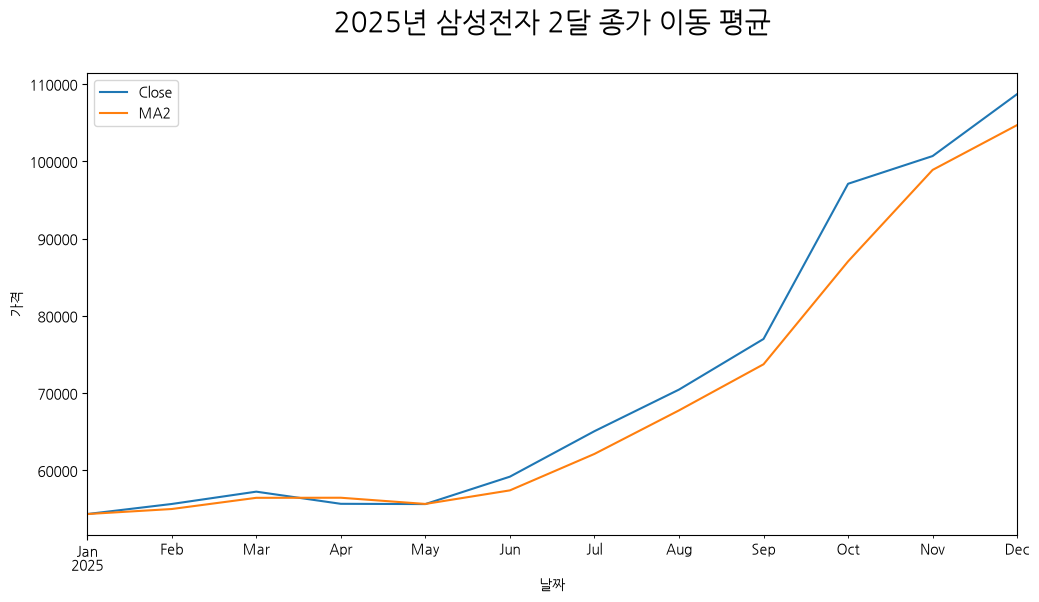

In [80]:
samsung_month_df.loc[:, ['Close', 'MA2']].plot(xlabel='날짜', ylabel='가격', figsize=[12, 6])
plt.title('2025년 삼성전자 2달 종가 이동 평균', fontsize=20, pad=30)
plt.show()

3달 종가 이동 평균 시각화

In [81]:
samsung_month_df['MA3'] = samsung_month_df.Close.rolling(window=3, min_periods=1).mean()
samsung_month_df

,Open,High,Low,Close,Volume,Change,MA2,MA3
Date,,,,,,,,
2025-01-31,54238.888889,55044.444444,53750.000000,54361.111111,1.904949e+07,-0.000711,54361.111111,54361.111111
2025-02-28,55465.000000,56220.000000,55025.000000,55665.000000,2.123153e+07,0.002120,55013.055556,55013.055556
2025-03-31,57075.000000,57960.000000,56535.000000,57260.000000,2.078140e+07,0.003160,56462.500000,55762.037037
2025-04-30,55840.909091,56372.727273,55286.363636,55686.363636,1.460492e+07,-0.001606,56473.181818,56203.787879
2025-05-30,55705.263158,56336.842105,55189.473684,55652.631579,1.400887e+07,0.000811,55669.497608,56199.665072
2025-06-30,59315.789474,59936.842105,58568.421053,59200.000000,1.917143e+07,0.003443,57426.315789,56846.331738
2025-07-31,64891.304348,65786.956522,64039.130435,65086.956522,2.137355e+07,0.007976,62143.478261,59979.862700
2025-08-29,70810.000000,71300.000000,70065.000000,70470.000000,1.414719e+07,-0.001104,67778.478261,64918.985507
2025-09-30,76677.272727,77595.454545,75900.000000,77022.727273,1.862918e+07,0.008649,73746.363636,70859.894598


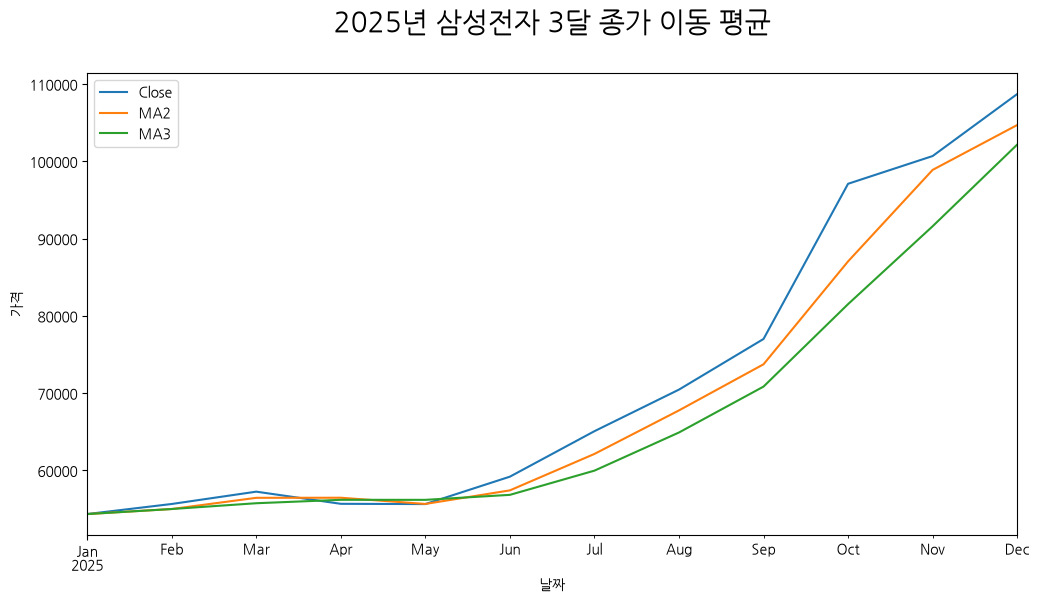

In [82]:
samsung_month_df.loc[:, ['Close', 'MA2', 'MA3']].plot(xlabel='날짜', ylabel='가격', figsize=[12, 6])
plt.title('2025년 삼성전자 3달 종가 이동 평균', fontsize=20, pad=30)
plt.show()

## 상승장인지 하락장인지 판별한다.

In [86]:
last_close = samsung_month_df.Close.iloc[-3] # 2달 전 종가
print(last_close)
price = samsung_month_df.Close.iloc[-1] # 이번달 종가
print(price)

if price > last_close:
    print('상승장')
elif price < last_close:
    print('하락장')
else:
    print('보합장')

97111.11111111111
108723.80952380953
상승장
